# System identification with bside: DRAM vs NUTS

[bside](https://github.com/ngalioto/bside) computes the marginal likelihood $p(y_{1:T} \mid \theta)$ of a state-space model with a Kalman filter. Its `Posterior` is a plain callable, so it works as a `target` for any sampler here. Because the Kalman filter is written in PyTorch, autograd also gives the gradient of the log-posterior, which makes gradient-based samplers (MALA, HMC, NUTS) available.

We estimate the 2x2 transition matrix $A$ of a discretized pendulum from 50 noisy measurements of position and velocity and compare DRAM (no gradients) with NUTS (gradients through the filter).

Observing both states matters: with position alone, rescaling the unobserved velocity trades $A_{12}$ against $A_{21}$ while barely changing the likelihood, so the posterior is a long thin ridge that every sampler crawls along.

This notebook needs bside installed: `pip install git+https://github.com/ngalioto/bside`.

In [1]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath('__file__'))))

import time
import torch
import matplotlib.pyplot as plt

import bside
from bside.sysid import Posterior
from mcmc_samplers import NUTS, DelayedRejectionAdaptiveMetropolis, SampleVisualizer, diagnostics

## Data and posterior

In [2]:
torch.manual_seed(0)
dt = 0.1
A_true = torch.linalg.matrix_exp(torch.tensor([[0.0, 1.0], [-9.81, 0.0]]) * dt)
Q = bside.PSDMatrix(0.01 * torch.eye(2))
C = bside.Matrix(torch.eye(2))  # observe position and velocity
R = bside.PSDMatrix(0.01 * torch.eye(2))

def make_ssm(A):
    return bside.SSM(
        xdim=2, ydim=2,
        dynamics=bside.LinearGaussianModel(model=bside.LinearModel(A), noise_cov=Q),
        observations=bside.LinearGaussianModel(model=bside.LinearModel(C), noise_cov=R),
    )

x0 = torch.tensor([1.5, 0.0])
_, y = make_ssm(bside.Matrix(A_true)).measure(x=x0, T=50, keep_y0=False, return_x=True)

# All four entries of A are unknown.
A = bside.Matrix(default=A_true, mask=torch.ones(2, 2, dtype=torch.bool), indices=torch.arange(4))
posterior = Posterior(
    filter=bside.KalmanFilter(model=make_ssm(A)),
    data=bside.Data(y=y),
    init_dist=bside.FilteringDistribution(mean=x0, cov=0.01 * torch.eye(2)),
)


def log_posterior(theta):
    # Some A matrices make the filter's covariance indefinite. Treat those as
    # impossible (log-density -inf, zero gradient) so samplers reject them.
    try:
        return posterior(theta)
    except torch.linalg.LinAlgError:
        return theta.sum() * 0.0 - float('inf')


class Counted:
    # Count target evaluations (a log-density + gradient counts as one).
    def __init__(self, f):
        self.f, self.calls = f, 0

    def __call__(self, x):
        self.calls += 1
        return self.f(x)

## Run both samplers

In [3]:
theta0 = A_true.flatten() + 0.01 * torch.randn(4)
labels = ['$A_{11}$', '$A_{12}$', '$A_{21}$', '$A_{22}$']
results = {}

target = Counted(log_posterior)
dram = DelayedRejectionAdaptiveMetropolis(
    target, theta0, cov=1e-4 * torch.eye(4), n0=200, generator=torch.Generator().manual_seed(0)
)
start = time.perf_counter()
samples, _ = dram(2000, burn_in=500, show_progress=False)
results['DRAM'] = (samples, time.perf_counter() - start, target.calls)

target = Counted(log_posterior)
nuts = NUTS(
    target, theta0, step_size=0.01, warmup=100, max_depth=4,
    generator=torch.Generator().manual_seed(0),
)
start = time.perf_counter()
samples, _ = nuts(300, burn_in=100, show_progress=False)
results['NUTS'] = (samples, time.perf_counter() - start, target.calls)

print(f"{'':6s} {'draws':>6s} {'min ESS':>8s} {'seconds':>8s} {'ESS/s':>7s} {'ESS/1000 evals':>15s}")
for name, (samples, seconds, calls) in results.items():
    ess = float(diagnostics.effective_sample_size(samples).min())
    print(f"{name:6s} {len(samples):6d} {ess:8.0f} {seconds:8.1f} {ess / seconds:7.2f} {1000 * ess / calls:15.1f}")

        draws  min ESS  seconds   ESS/s  ESS/1000 evals
DRAM     1500       80    210.6    0.38            23.9
NUTS      200       45    515.4    0.09            17.0


## Compare the posteriors

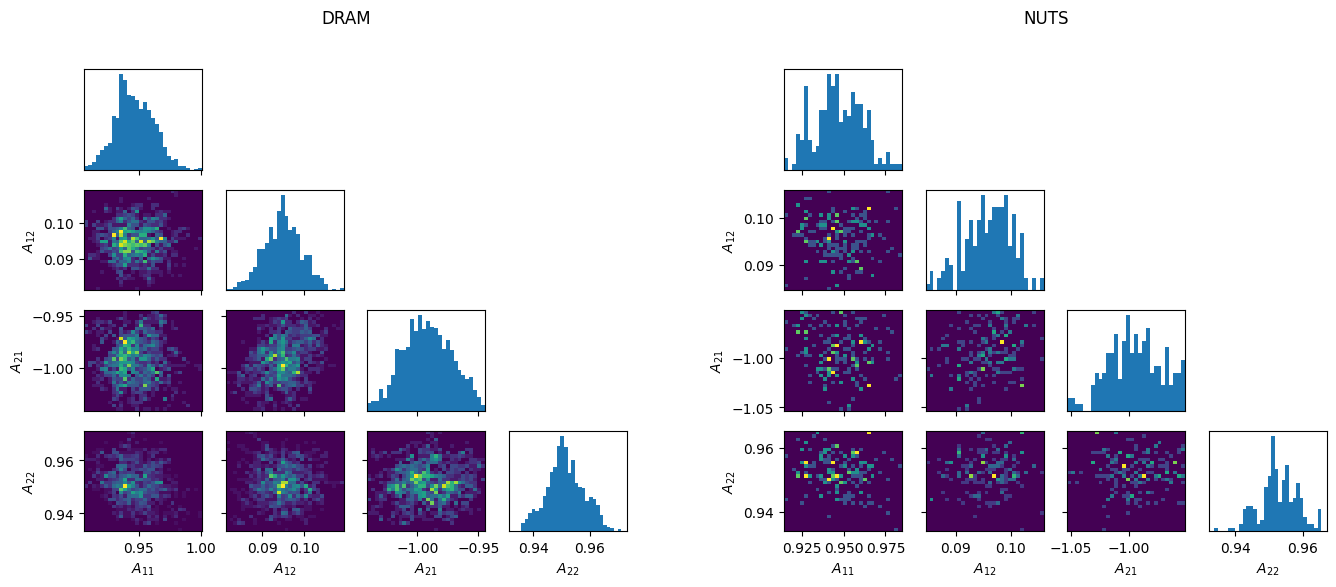

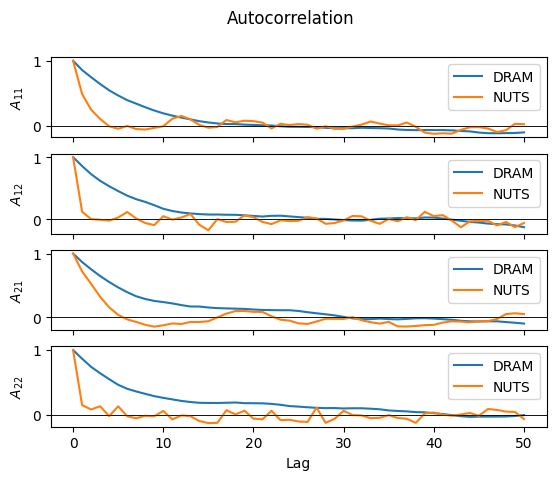

true A: [0.951349675655365, 0.09837299585342407, -0.9650391936302185, 0.951349675655365]
DRAM posterior mean: [0.9465, 0.0949, -0.9916, 0.9515]
NUTS posterior mean: [0.9471, 0.0958, -0.9945, 0.9527]


In [4]:
fig = plt.figure(figsize=(14, 6))
for subfig, (name, (samples, _, _)) in zip(fig.subfigures(1, 2), results.items()):
    SampleVisualizer(samples).triangular_hist(bins=30, labels=labels, titles=[name], fig=subfig)

axs = None
for name, (samples, _, _) in results.items():
    _, (axs,) = SampleVisualizer(samples).autocorrelation(
        max_lag=50, labels=labels, titles=['Autocorrelation'], axs=axs, label=name
    )
plt.show()

print('true A:', A_true.flatten().tolist())
for name, (samples, _, _) in results.items():
    print(f'{name} posterior mean:', [round(v, 4) for v in samples.mean(0).tolist()])

**Takeaway.** NUTS needs far fewer draws for the same effective sample size, but each NUTS step runs several forward and backward passes through the Kalman filter, so compare the samplers per second and per target evaluation, not per draw. Which one wins depends on the cost of the filter and on the dimension of $\theta$: gradient-based samplers pull ahead as the number of parameters grows.